# Xiao_Hongwei_HW4
Name: Hongwei Xiao  
GitHub username: Ga9a  
DSCI 552: Homework 4

## 1. Reuse the HW3 data and features
HW3 is submitted separately. I repeat the data loading here so this notebook can run on its own.
The test files are datasets 1 and 2 for each bending activity and datasets 1, 2, and 3 for each other activity.
Each file remains one instance, even when its time series are split into smaller pieces.

In [1]:
from pathlib import Path
import re, warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.special import expit, logit
from scipy.optimize import linprog
from scipy.stats import norm
import statsmodels.api as sm
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MaxAbsScaler, label_binarize
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score, classification_report)
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

ROOT = Path.cwd() if (Path.cwd() / 'data/AReM').exists() else Path.cwd().parent
DATA = ROOT / 'data/AReM'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
SEED = 42
ACTIVITIES = ['bending1','bending2','cycling','lying','sitting','standing','walking']
STATS = ['min','max','mean','median','std','q1','q3']
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_rows', 50)
pd.set_option('display.precision', 4)

arrays, records = [], []
for activity in ACTIVITIES:
    paths = sorted((DATA/activity).glob('dataset*.csv'), key=lambda p:int(p.stem[7:]))
    for path in paths:
        rows = [[float(v) for v in re.split(r'[,\s]+', line.strip().rstrip(','))]
                for line in path.read_text(encoding='utf-8-sig').splitlines()
                if line.strip() and not line.lstrip().startswith('#')]
        a = np.asarray(rows)
        assert a.shape[1] == 7 and np.isfinite(a).all()
        arrays.append(a[:,1:])
        number = int(path.stem[7:])
        test = number <= (2 if activity.startswith('bending') else 3)
        records.append(dict(activity=activity, file=f'{activity}/{path.name}',
                            length=len(a), split='test' if test else 'train'))
metadata = pd.DataFrame(records)
train_mask = metadata.split.eq('train').to_numpy()
test_mask = ~train_mask
y_train = metadata.loc[train_mask,'activity'].str.startswith('bending').astype(int).to_numpy()
y_test = metadata.loc[test_mask,'activity'].str.startswith('bending').astype(int).to_numpy()
ym_train = metadata.loc[train_mask,'activity'].to_numpy()
ym_test = metadata.loc[test_mask,'activity'].to_numpy()
assert (len(arrays), train_mask.sum(), test_mask.sum()) == (88,69,19)
display(pd.crosstab(metadata.activity, metadata.split).reindex(ACTIVITIES))
display(metadata[metadata.length != 480])

def extract_features(l):
    rows = []
    columns = [f'{stat}_s{s}_part{k}' for k in range(1,l+1)
               for s in range(1,7) for stat in STATS]
    for a in arrays:
        values = []
        for chunk in np.array_split(a, l):
            for series in chunk.T:
                values.extend([series.min(), series.max(), series.mean(), np.median(series),
                               series.std(ddof=1), *np.quantile(series,[.25,.75])])
        rows.append(values)
    result = pd.DataFrame(rows, columns=columns)
    assert result.shape == (88,42*l) and np.isfinite(result).all().all()
    return result

# These statistics use only the current file, so computing them before CV is safe.
features = {l:extract_features(l) for l in range(1,21)}
Xtrain = {l:f.loc[train_mask].reset_index(drop=True) for l,f in features.items()}
Xtest = {l:f.loc[test_mask].reset_index(drop=True) for l,f in features.items()}
metadata.to_csv(OUT/'instance_split.csv', index=False)
print('Binary training counts:', dict(zip(*np.unique(y_train, return_counts=True))))

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


,activity,file,length,split
50,sitting,sitting/dataset8.csv,479,train


Binary training counts: {np.int64(0): np.int64(60), np.int64(1): np.int64(9)}


The space-separated file `bending2/dataset4.csv` is read by the same parser as the other files.
`sitting/dataset8.csv` has 479 rows. I keep its observed rows and divide them as evenly as possible.
For every segment I calculate minimum, maximum, mean, median, sample standard deviation,
and the first and third quartiles for all six series. This gives $42l$ features per instance.

## 2. Time series classification, Part 2
### (a) Binary classification with logistic regression
#### (i) Scatter plots before splitting
I use mean, standard deviation, and maximum, which were my three choices in HW3.
The plot uses series 1, 2, and 6 from the training set. Blue is other activity and orange is bending.
Only one triangle is shown because the other triangle repeats the same pairs.

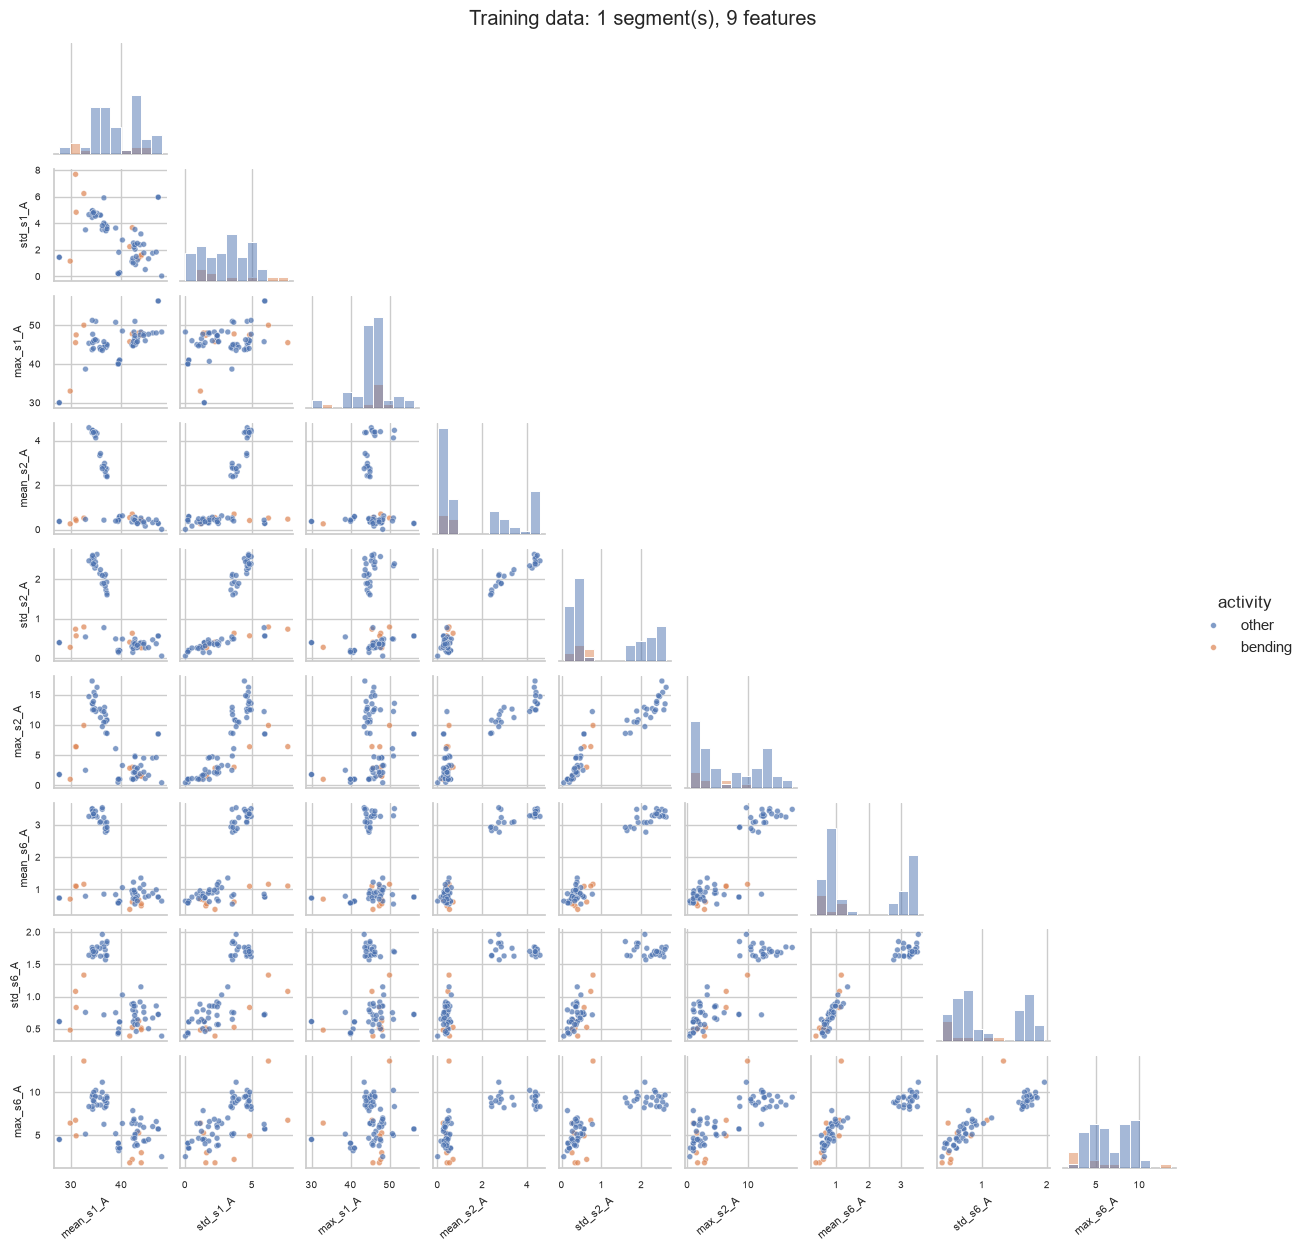

In [2]:
def feature_pairplot(l, filename):
    cols = [f'{stat}_s{s}_part{k}' for k in range(1,l+1)
            for s in [1,2,6] for stat in ['mean','std','max']]
    frame = Xtrain[l][cols].copy()
    frame.columns = [name.replace('_part1','_A').replace('_part2','_B') for name in cols]
    frame['activity'] = np.where(y_train == 1, 'bending', 'other')
    g = sns.pairplot(frame, hue='activity', hue_order=['other','bending'], corner=True,
                     diag_kind='hist', height=1.35,
                     plot_kws={'s':17,'alpha':.7}, diag_kws={'bins':10})
    for ax in g.axes.flat:
        if ax is not None:
            ax.set_xlabel(ax.get_xlabel(), fontsize=8, rotation=40, ha='right')
            ax.set_ylabel(ax.get_ylabel(), fontsize=8)
            ax.tick_params(labelsize=7)
    g.fig.suptitle(f'Training data: {l} segment(s), {len(cols)} features', y=1.01)
    g.savefig(OUT/filename, dpi=120, bbox_inches='tight')
    plt.show()
feature_pairplot(1, 'a_i_scatter.png')

#### (ii) Split each series into two parts
The first and second halves each supply nine plotted features. The following plot includes all
18 features, including pairs from different halves. The names identify the original series and half.
In the plot labels, `s1`, `s2`, and `s6` identify the series; `A` and `B` identify the first and second parts.

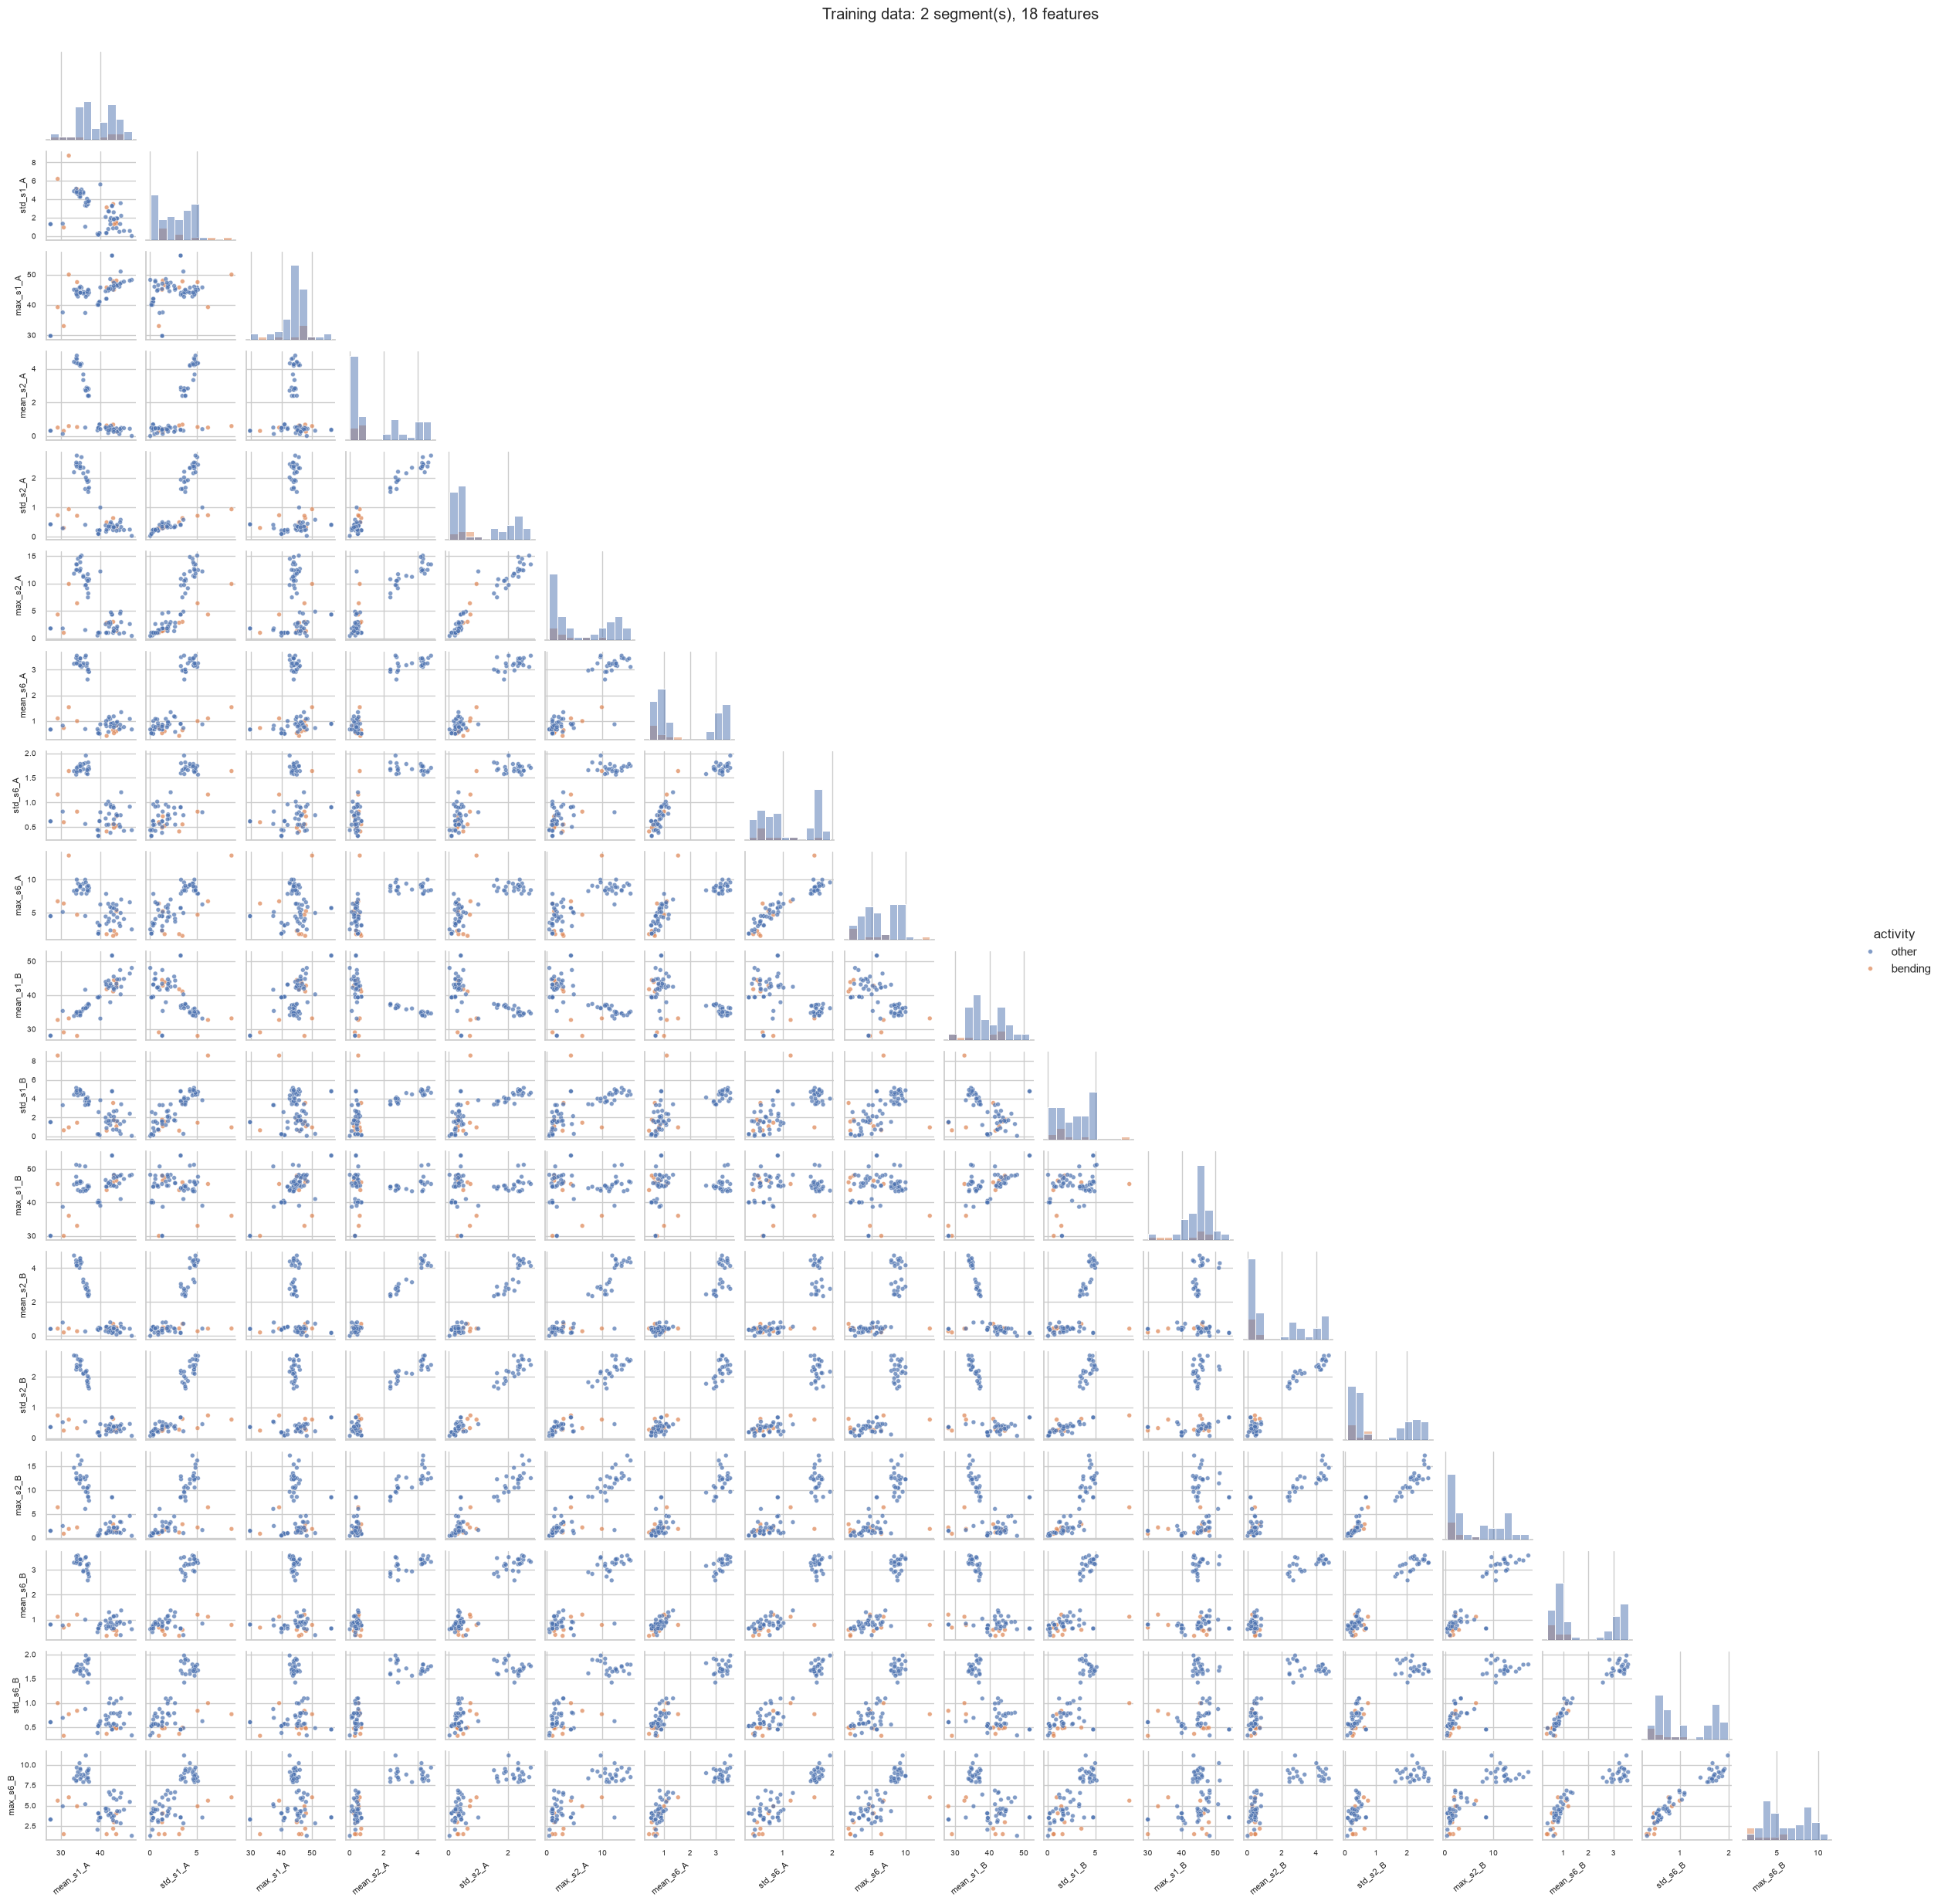

In [3]:
feature_pairplot(2, 'a_ii_scatter.png')

Bending usually has small means and standard deviations for series 2 and 6. Some other activities
have similar values, though, and series 1 has quite a bit of overlap. Splitting into two halves does
not make the groups look much clearer to me. Many features from the first and second halves look
similar. I use cross-validation below to see whether splitting actually helps the classifier.

#### (iii) Choose the number of segments and features by cross-validation
I use RFE, the backward-selection option allowed in the question. I try $l=1$ through $20$ and
$p\in\{1,2,3,5,10,15,20\}$. These are the feature counts I compare; I do not test every possible count.
At each step, RFE removes 25% of the original number of features until it reaches $p$.

I use stratified five-fold CV, with shuffling and seed 42. Stratification keeps both binary classes
in each fold. For each split, I fit the scaler and select features using that fold's training data.
Selecting features from all 69 training files before CV would be wrong because the validation
labels would already have helped choose the features. The 19 test files stay out of this process.
Splitting a file into segments adds columns, not separate samples.

The logistic regression has no penalty (`C=np.inf`). I set `max_iter=1000` and tolerance $10^{-4}$.
Stopping the solver gives finite numbers to use for prediction, but it does not solve the issue of
an infinite MLE when the classes separate. For tied CV scores, I choose smaller $l$, then smaller
$p$ (or smaller $C$ for L1). Since CV is also used to pick the model, I check the final choice on
the test set.

The warning below is about the seven-class folds prepared for part (c). Both binary classes are
present in every binary fold.

In [4]:
binary_cv = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xtrain[1],y_train))
multi_cv = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xtrain[1],ym_train))

def plain_logit():
    return LogisticRegression(C=np.inf, solver='lbfgs', max_iter=1000, tol=1e-4)

def search_segments(name, pipeline, grid, target, folds):
    tables = []
    for l in range(1,21):
        search = GridSearchCV(pipeline, grid, cv=folds, scoring='accuracy',
                              refit=False, n_jobs=1, error_score='raise')
        with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
            warnings.simplefilter('always', ConvergenceWarning)
            search.fit(Xtrain[l], target)
        table = pd.DataFrame(search.cv_results_)
        table['l'] = l
        table['convergence_warnings'] = sum(issubclass(w.category,ConvergenceWarning) for w in caught)
        tables.append(table)
        print(f'{name}: l={l:2d}, best CV={table.mean_test_score.max():.4f}, '
              f'convergence warnings={int(table.convergence_warnings.iloc[0])}', flush=True)
    result = pd.concat(tables,ignore_index=True)
    params = sorted(c for c in result if c.startswith('param_'))
    result = result.sort_values(['mean_test_score','l']+params,
                                ascending=[False,True]+[True]*len(params), kind='stable')
    result.to_csv(OUT/f'{name}_cv.csv', index=False)
    best = result.iloc[0]
    model = clone(pipeline).set_params(**best['params'])
    with threadpool_limits(limits=1):
        model.fit(Xtrain[int(best.l)], target)
    print('Chosen:', {'l':int(best.l), **best['params']})
    display(result[['l']+params+['mean_test_score','std_test_score']].head(10))
    return model, int(best.l), result

rfe_pipeline = Pipeline([('scale',StandardScaler()),
                         ('rfe',RFE(plain_logit(),step=.25))])
rfe_model, rfe_l, rfe_cv = search_segments('rfe', rfe_pipeline,
    {'rfe__n_features_to_select':[1,2,3,5,10,15,20]}, y_train, binary_cv)
rfe_p = int(rfe_model.named_steps['rfe'].n_features_)
selected = Xtrain[rfe_l].columns[rfe_model.named_steps['rfe'].support_].tolist()
print('Selected features:', selected)

E:\PDF New Homework- 8 Sets\HW1_Reference\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


rfe: l= 1, best CV=0.9857, convergence warnings=0


rfe: l= 2, best CV=0.9571, convergence warnings=0


rfe: l= 3, best CV=0.9714, convergence warnings=0


rfe: l= 4, best CV=0.9571, convergence warnings=0


...

rfe: l=19, best CV=0.9571, convergence warnings=0


rfe: l=20, best CV=0.9714, convergence warnings=0


Chosen: {'l': 1, 'rfe__n_features_to_select': 20}


,l,param_rfe__n_features_to_select,mean_test_score,std_test_score
6,1,20,0.9857,0.0286
5,1,15,0.9714,0.0350
15,3,2,0.9714,0.0350
81,12,10,0.9714,0.0350
137,20,10,0.9714,0.0350
138,20,15,0.9714,0.0350
41,6,20,0.9571,0.0571
139,20,20,0.9571,0.0571
3,1,5,0.9571,0.0571
4,1,10,0.9571,0.0571


Selected features: ['min_s1_part1', 'max_s1_part1', 'mean_s1_part1', 'median_s1_part1', 'q3_s1_part1', 'max_s2_part1', 'max_s3_part1', 'median_s3_part1', 'std_s3_part1', 'q3_s3_part1', 'max_s4_part1', 'median_s4_part1', 'min_s5_part1', 'max_s5_part1', 'mean_s5_part1', 'q1_s5_part1', 'q3_s5_part1', 'median_s6_part1', 'std_s6_part1', 'q1_s6_part1']


#### (iv) Training confusion matrix, ROC, coefficients, and p-values
Bending is class 1. I predict bending when its probability is at least 0.5.
The coefficients below are for standardized features. Before calculating p-values, I check for
separation, since ordinary Wald p-values need a finite, identifiable maximum-likelihood estimate.

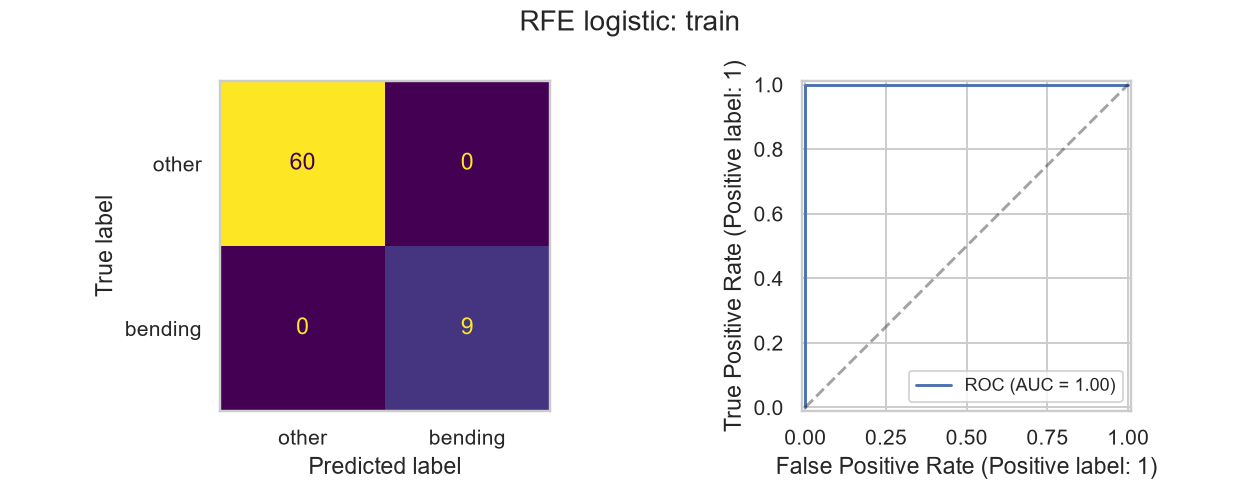

accuracy             1.0
error                0.0
balanced_accuracy    1.0
auc                  1.0
dtype: float64

,term,coefficient,p_value
0,intercept,-10.4836,NaN
1,min_s1_part1,-1.6968,NaN
2,max_s1_part1,1.3035,NaN
3,mean_s1_part1,-1.1545,NaN
4,median_s1_part1,-0.7214,NaN
5,q3_s1_part1,-2.2247,NaN
6,max_s2_part1,-1.4966,NaN
7,max_s3_part1,1.1730,NaN
8,median_s3_part1,-0.6491,NaN
9,std_s3_part1,-1.0416,NaN


Complete separation: no finite unpenalized MLE; ordinary Wald p-values are undefined.


In [5]:
def binary_report(y, probabilities, title, filename):
    pred = (probabilities >= .5).astype(int)
    fig, axes = plt.subplots(1,2,figsize=(9,3.6))
    ConfusionMatrixDisplay.from_predictions(y,pred,labels=[0,1],display_labels=['other','bending'],
                                            colorbar=False,ax=axes[0])
    RocCurveDisplay.from_predictions(y,probabilities,ax=axes[1],name='ROC')
    axes[0].grid(False)
    axes[1].legend(loc='lower right', fontsize=9)
    axes[1].plot([0,1],[0,1],'k--',alpha=.4)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(OUT/filename,dpi=140); plt.show()
    return dict(accuracy=accuracy_score(y,pred), error=1-accuracy_score(y,pred),
                balanced_accuracy=balanced_accuracy_score(y,pred), auc=roc_auc_score(y,probabilities))

rfe_train_prob = rfe_model.predict_proba(Xtrain[rfe_l])[:,1]
rfe_train_metrics = binary_report(y_train,rfe_train_prob,'RFE logistic: training','a_iv_train.png')
display(pd.Series(rfe_train_metrics))
Z = rfe_model.named_steps['scale'].transform(Xtrain[rfe_l])[:,rfe_model.named_steps['rfe'].support_]
design = sm.add_constant(Z,has_constant='add')
signed = (2*y_train-1)[:,None]*design
sep_check = linprog(np.zeros(design.shape[1]), A_ub=-signed,
                    b_ub=-np.ones(len(y_train)), bounds=[(None,None)]*design.shape[1],method='highs')
separated = bool(sep_check.success)
est = rfe_model.named_steps['rfe'].estimator_
coef_table = pd.DataFrame({'term':['intercept']+selected,
                          'coefficient':np.r_[est.intercept_,est.coef_.ravel()],
                          'p_value':np.nan})
inference_note = ''
if separated:
    inference_note = 'Complete separation: no finite unpenalized MLE; ordinary Wald p-values are undefined.'
elif np.linalg.matrix_rank(design) < design.shape[1]:
    inference_note = 'Rank-deficient design: individual Wald p-values are not identifiable.'
else:
    try:
        with warnings.catch_warnings(record=True) as infer_warnings:
            warnings.simplefilter('always')
            inference_fit = sm.Logit(y_train,design).fit(disp=False,maxiter=1000)
        if not inference_fit.mle_retvals['converged'] or infer_warnings:
            inference_note = 'The MLE did not give a warning-free converged fit; p-values are unavailable.'
        else:
            coef_table['coefficient'] = inference_fit.params
            coef_table['p_value'] = inference_fit.pvalues
            inference_note = 'Wald p-values are conditional on the selected features; selection is not accounted for.'
    except (np.linalg.LinAlgError, ValueError) as exc:
        inference_note = f'Unstable MLE: {type(exc).__name__}; p-values are unavailable.'
display(coef_table)
print(inference_note)
coef_table.to_csv(OUT/'rfe_coefficients.csv', index=False)

#### (v) Test accuracy
I apply the training scaler and selected columns to the test instances, with the same $l$ segments.

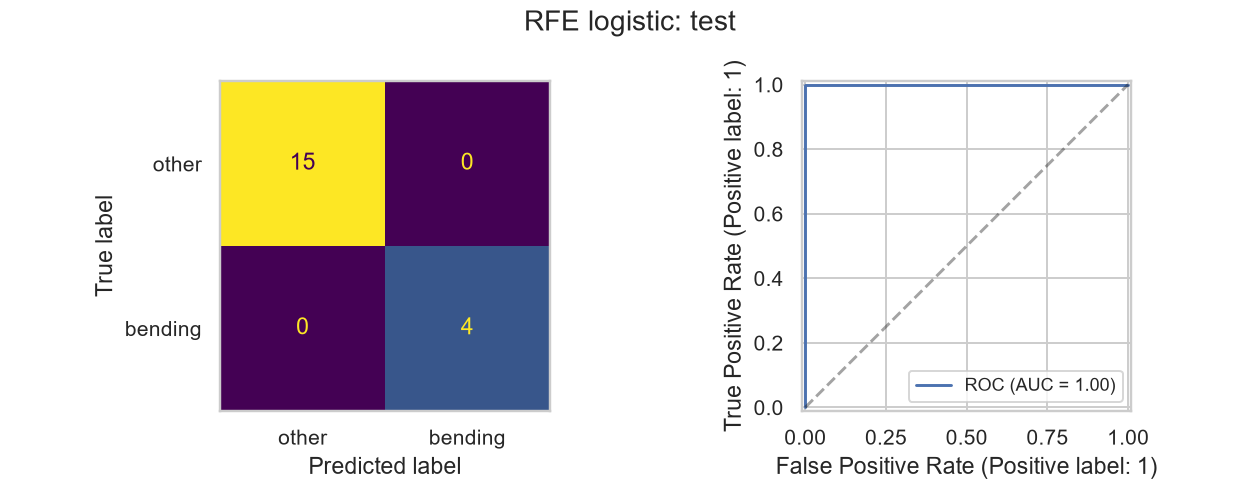

,set,accuracy,error,balanced_accuracy,auc
0,CV (selection),0.9857,NaN,NaN,NaN
1,train,1.0000,0.0,1.0,1.0
2,test,1.0000,0.0,1.0,1.0


In [6]:
rfe_test_prob = rfe_model.predict_proba(Xtest[rfe_l])[:,1]
rfe_test_metrics = binary_report(y_test,rfe_test_prob,'RFE logistic: test','a_v_test.png')
display(pd.DataFrame([{'set':'CV (selection)','accuracy':rfe_cv.iloc[0].mean_test_score},
                      {'set':'train',**rfe_train_metrics},{'set':'test',**rfe_test_metrics}]))

The best pair in my search is $l=1$ and $p=20$. CV accuracy is 98.57%, and test accuracy is 100%:
all 15 other-activity files and all 4 bending files are correct. Training accuracy and AUC are also 1.00.

The training classes are completely separated by the selected features. The coefficients shown
are where the solver stopped, so they are not a stable finite MLE. I leave the p-values as unavailable
for that reason. There are only 19 test files, so the perfect test score does not mean every new
activity file would be classified correctly.

#### (vi) Separation and numerical instability
Yes, the separation check above confirms it. When a line or hyperplane separates every training
example correctly, increasing the coefficients keeps improving the unpenalized likelihood.
There is no finite maximum-likelihood estimate. Probabilities get close to 0 and 1, and the
information matrix becomes nearly singular, which causes problems with standard errors and p-values.
Running more iterations does not fix this.

The linear program checks whether all signed margins can be at least 1. In part (b), the L1 penalty
limits the coefficient sizes. The usual unpenalized Wald p-values still do not apply to that L1 fit.

#### (vii) Class imbalance and case-control sampling
The training set has 60 other-activity files and only 9 bending files. Always predicting other would
give $60/69=86.96\%$ accuracy. I therefore check balanced accuracy and the confusion matrices too.
For case-control sampling, I keep all 9 bending files and randomly choose 9 other-activity files
without replacement. I refit the scaler and RFE on these 18 files, using the same $(l,p)$ as above.

The bending proportion in the sample is $1/2$, compared with $9/69$ in the original training set.
I correct the intercept by adding
$\operatorname{logit}(9/69)-\operatorname{logit}(1/2)=\log(9/60)$.
The test labels are not used in this correction. I show the results before and after adjusting it.
Sampling throws away some controls, and separation can still make the fitted probabilities unreliable.

Sample counts: [9 9]
Intercept: 0.7092134776728006 adjustment: -1.8971199848858813 adjusted intercept: -1.1879065072130808


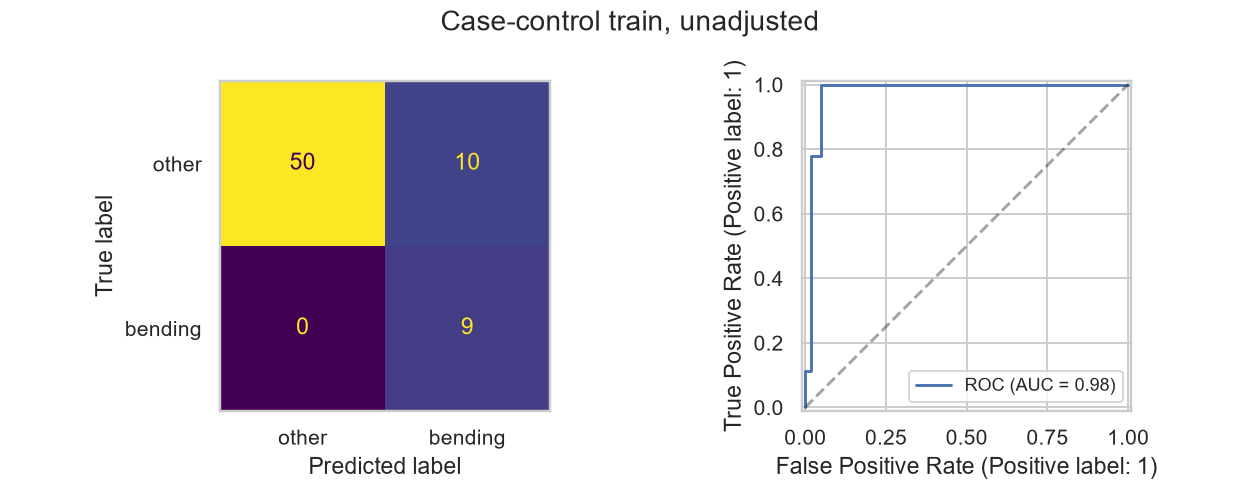

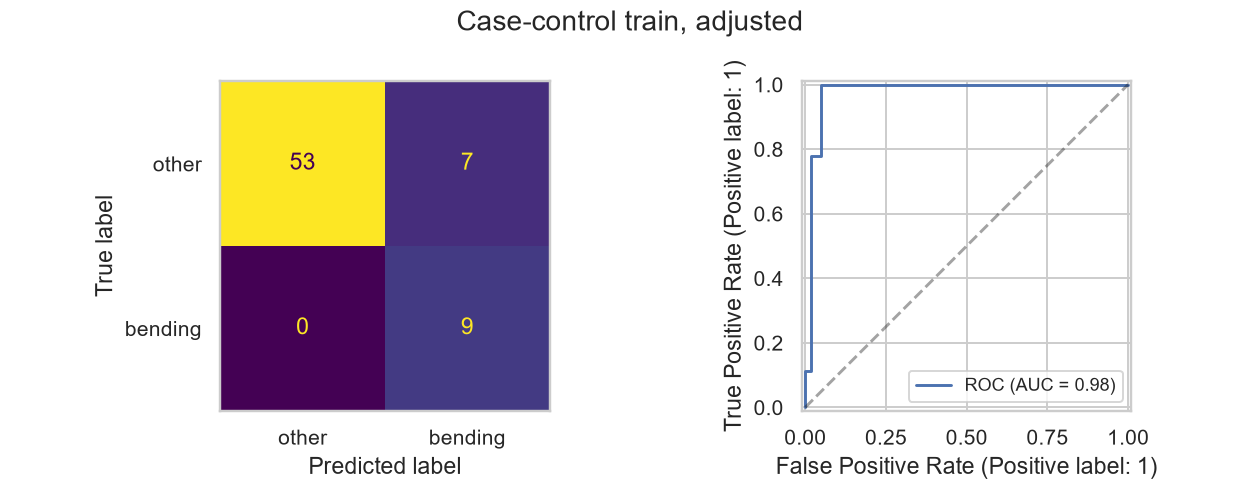

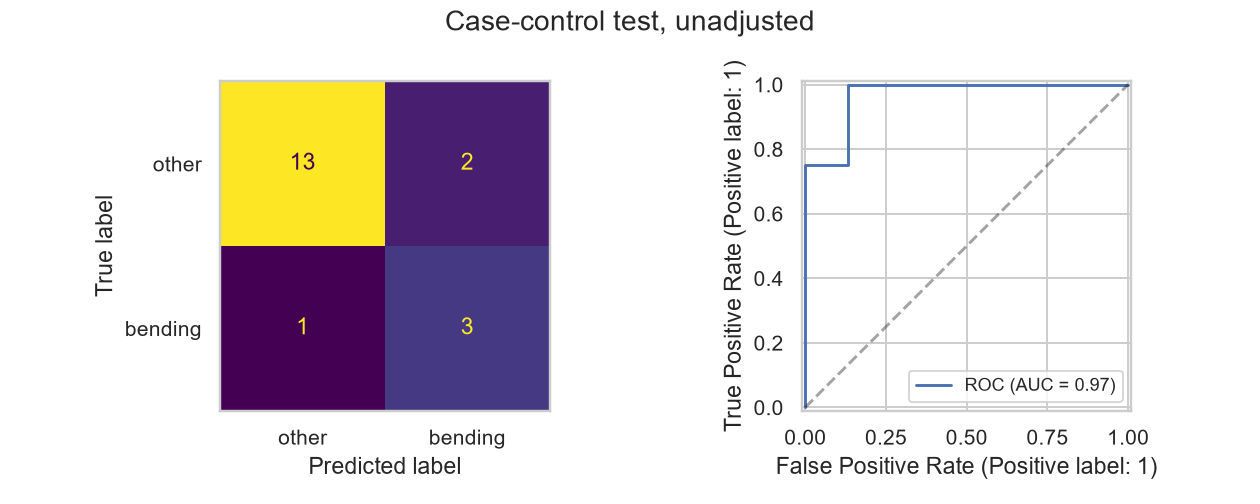

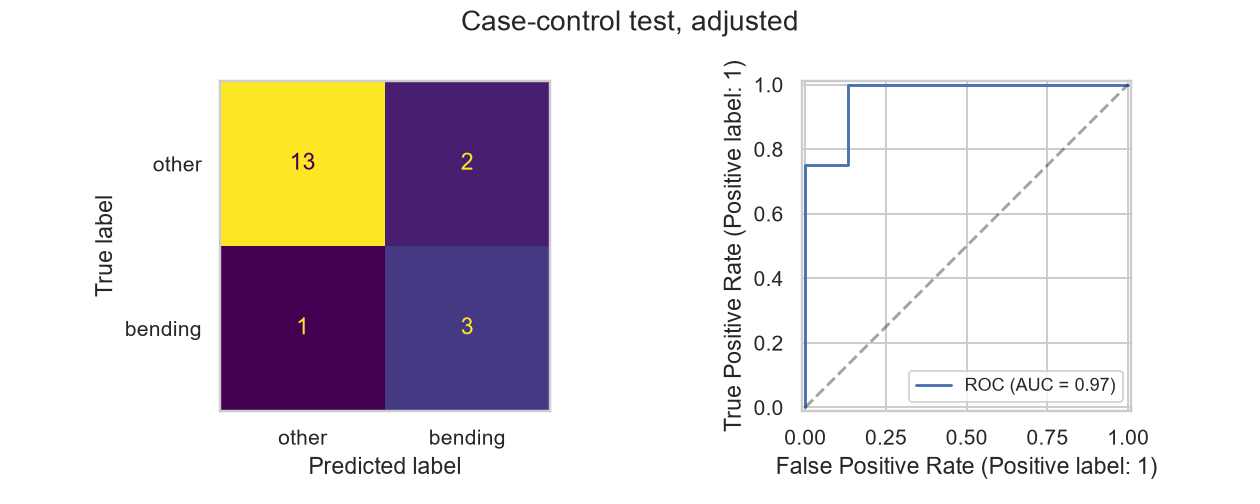

,set,adjusted,accuracy,error,balanced_accuracy,auc
0,train,False,0.8551,0.1449,0.9167,0.9778
1,train,True,0.8986,0.1014,0.9417,0.9778
2,test,False,0.8421,0.1579,0.8083,0.9667
3,test,True,0.8421,0.1579,0.8083,0.9667


In [7]:
rng = np.random.default_rng(SEED)
case_ids = np.flatnonzero(y_train == 1)
control_ids = rng.choice(np.flatnonzero(y_train == 0),size=len(case_ids),replace=False)
sample_ids = np.r_[case_ids,control_ids]
case_model = clone(rfe_model)
with threadpool_limits(limits=1):
    case_model.fit(Xtrain[rfe_l].iloc[sample_ids],y_train[sample_ids])
intercept_adjustment = logit(y_train.mean())-logit(y_train[sample_ids].mean())
case_est = case_model.named_steps['rfe'].estimator_
print('Sample counts:',np.bincount(y_train[sample_ids]))
print('Intercept:',case_est.intercept_[0], 'adjustment:',intercept_adjustment,
      'adjusted intercept:',case_est.intercept_[0]+intercept_adjustment)
case_rows=[]
for set_name,X,y in [('train',Xtrain[rfe_l],y_train),('test',Xtest[rfe_l],y_test)]:
    scores = case_model.decision_function(X)
    for adjusted in [False,True]:
        probs = expit(scores+(intercept_adjustment if adjusted else 0))
        label = f'Case-control {set_name}, '+('adjusted' if adjusted else 'unadjusted')
        metrics = binary_report(y,probs,label,f'a_vii_{set_name}_{adjusted}.png')
        case_rows.append(dict(set=set_name,adjusted=adjusted,**metrics))
case_results = pd.DataFrame(case_rows)
display(case_results)
case_results.to_csv(OUT/'case_control_results.csv',index=False)

The original training confusion matrix shows the imbalance: 60 controls and 9 cases, with no
classification errors. With case-control sampling, training accuracy is 85.51% before the intercept
correction and 89.86% after it. Both versions get 84.21% on the test set. They misclassify two
other-activity files and one bending file. Test AUC is 0.9667 in both cases because changing the
intercept does not change the order of the scores.

Sampling did not help here. It removed 51 control files, and fitting 20 selected features to only
18 files leaves very little data for the model.

### (b) Binary classification using L1-penalized logistic regression
#### (i) Tune the penalty and segmentation
I try $l=1,\ldots,20$ and $C\in\{0.001,0.01,0.1,1,10,100\}$ using the same five folds.
$C$ is inverse penalty strength, so smaller values mean stronger regularization. Scaling stays
inside CV. The liblinear solver fits the binary L1 model, which can set coefficients exactly to zero.

binary_l1: l= 1, best CV=0.9571, convergence warnings=0


binary_l1: l= 2, best CV=0.9571, convergence warnings=0


binary_l1: l= 3, best CV=0.9571, convergence warnings=0


binary_l1: l= 4, best CV=0.9571, convergence warnings=0


binary_l1: l= 5, best CV=0.9418, convergence warnings=0


...

binary_l1: l=19, best CV=0.9857, convergence warnings=0


binary_l1: l=20, best CV=0.9714, convergence warnings=0


Chosen: {'l': 19, 'model__C': 1}


,l,param_model__C,mean_test_score,std_test_score
111,19,1.0,0.9857,0.0286
63,11,1.0,0.9714,0.0350
69,12,1.0,0.9714,0.0350
70,12,10.0,0.9714,0.0350
75,13,1.0,0.9714,0.0350
81,14,1.0,0.9714,0.0350
105,18,1.0,0.9714,0.0350
106,18,10.0,0.9714,0.0350
107,18,100.0,0.9714,0.0350
112,19,10.0,0.9714,0.0350


Nonzero coefficients: 9 of 798


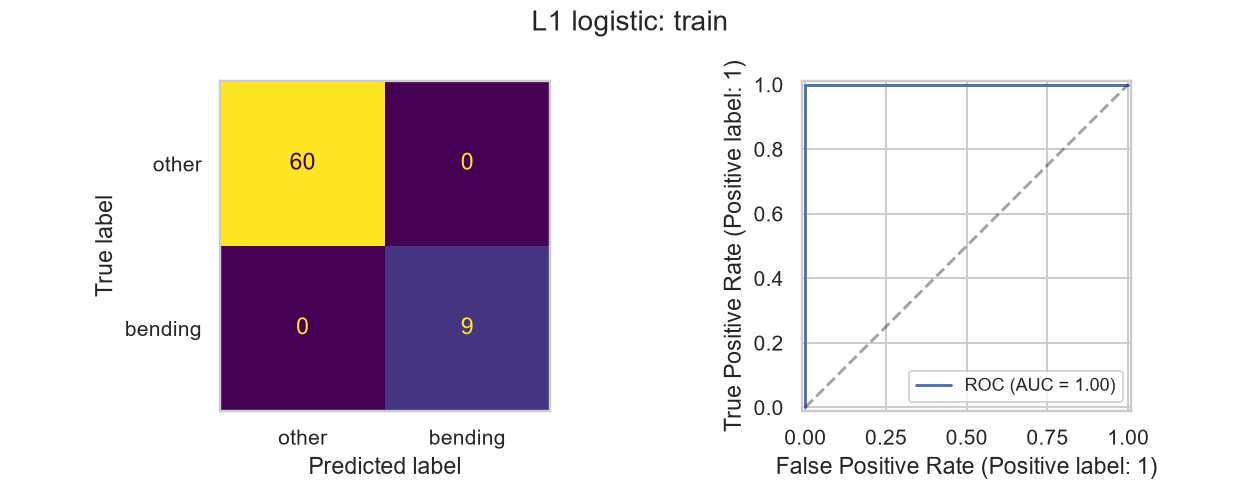

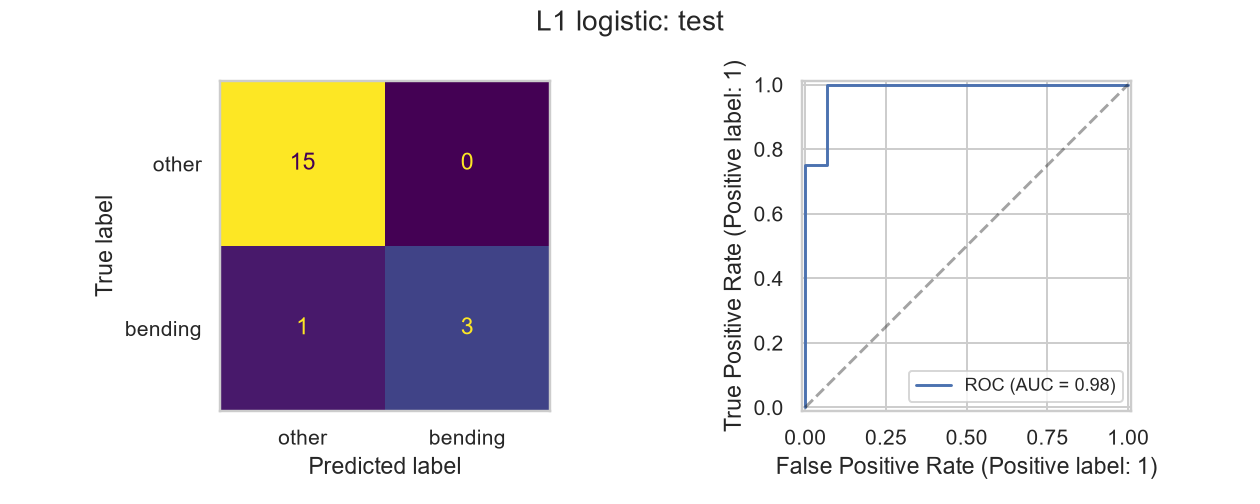

,method,l,p,C,cv_accuracy,train_accuracy,accuracy,error,balanced_accuracy,auc
0,RFE logistic,1,20,inf,0.9857,1.0,1.0000,0.0000,1.000,1.0000
1,L1 logistic,19,9,1.0,0.9857,1.0,0.9474,0.0526,0.875,0.9833


In [8]:
l1_pipeline = Pipeline([('scale',StandardScaler()),('model',LogisticRegression(
    solver='liblinear',l1_ratio=1,max_iter=5000,tol=1e-5,random_state=SEED))])
l1_model,l1_l,l1_cv = search_segments('binary_l1',l1_pipeline,
    {'model__C':[.001,.01,.1,1,10,100]},y_train,binary_cv)
l1_nnz = int(np.count_nonzero(l1_model.named_steps['model'].coef_))
print('Nonzero coefficients:',l1_nnz,'of',42*l1_l)
l1_train_metrics = binary_report(y_train,l1_model.predict_proba(Xtrain[l1_l])[:,1],
                                'L1 logistic: training','b_i_train.png')
l1_test_metrics = binary_report(y_test,l1_model.predict_proba(Xtest[l1_l])[:,1],
                               'L1 logistic: test','b_i_test.png')
binary_results = pd.DataFrame([
    dict(method='RFE logistic',l=rfe_l,p=rfe_p,C=np.inf,cv_accuracy=rfe_cv.iloc[0].mean_test_score,
         train_accuracy=rfe_train_metrics['accuracy'],**rfe_test_metrics),
    dict(method='L1 logistic',l=l1_l,p=l1_nnz,C=l1_model.named_steps['model'].C,
         cv_accuracy=l1_cv.iloc[0].mean_test_score,train_accuracy=l1_train_metrics['accuracy'],**l1_test_metrics)])
display(binary_results)
binary_results.to_csv(OUT/'binary_comparison.csv',index=False)

#### (ii) Comparison with feature selection
L1 chooses $l=19$ and $C=1$, keeping 9 nonzero coefficients out of 798 features.
Its CV accuracy is 98.57%, the same as RFE. RFE gets all 19 test files correct, while L1 gets 18
correct and misses one bending file. RFE is slightly better on this test set.

For part (a), I used the allowed RFE option, so I am comparing L1 with RFE here. I did not fit a
separate model selected by p-values. L1 was easier to set up because it selects variables during
fitting. Selecting by p-values would also run into the separation problem found above.

### (c) Multiclass classification
#### (i) L1 multinomial logistic regression
I now use all seven activity labels and fit multinomial logistic regression with the saga solver.
I try $l=1,\ldots,20$ and $C\in\{0.01,0.1,1,10\}$. I again use five-fold stratified CV with seed 42,
this time stratifying by the seven activity labels.

Bending2 has only four training files, so one validation fold has no bending2 example. All seven
classes are still present in each training fold. I can calculate validation accuracy, but with so
few examples, the results for the smaller classes can vary quite a bit.

For each ROC curve, I treat one activity as positive and the other six as negative. I use that
activity's predicted probability as the score. I also report the average one-vs-rest AUC across classes.

multinomial_l1: l= 1, best CV=0.9000, convergence warnings=0


multinomial_l1: l= 2, best CV=0.8692, convergence warnings=0


multinomial_l1: l= 3, best CV=0.8714, convergence warnings=0


multinomial_l1: l= 4, best CV=0.8714, convergence warnings=0


multinomial_l1: l= 5, best CV=0.8714, convergence warnings=0


...

multinomial_l1: l=19, best CV=0.8132, convergence warnings=0


multinomial_l1: l=20, best CV=0.8857, convergence warnings=0


Chosen: {'l': 1, 'model__C': 1}


,l,param_model__C,mean_test_score,std_test_score
2,1,1.0,0.9000,0.0857
66,17,1.0,0.8857,0.0728
78,20,1.0,0.8857,0.0571
3,1,10.0,0.8714,0.0700
15,4,10.0,0.8714,0.0700
19,5,10.0,0.8714,0.0700
11,3,10.0,0.8714,0.0833
35,9,10.0,0.8714,0.0948
34,9,1.0,0.8703,0.0523
7,2,10.0,0.8692,0.0300


Final fit iterations: [395]


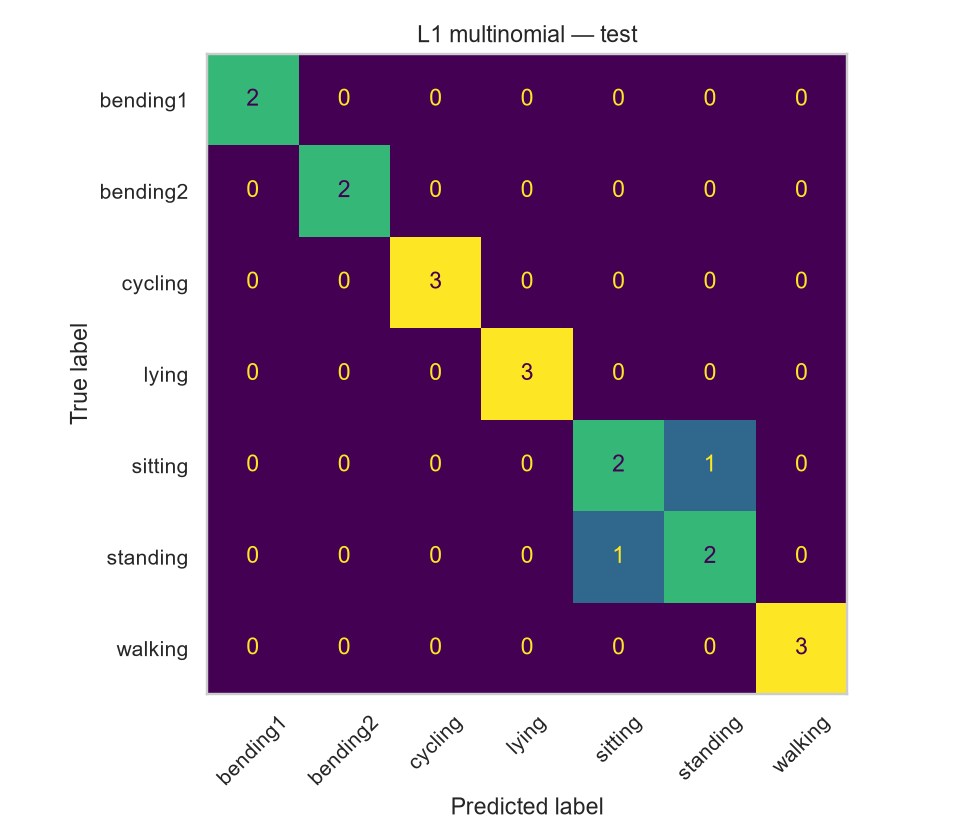

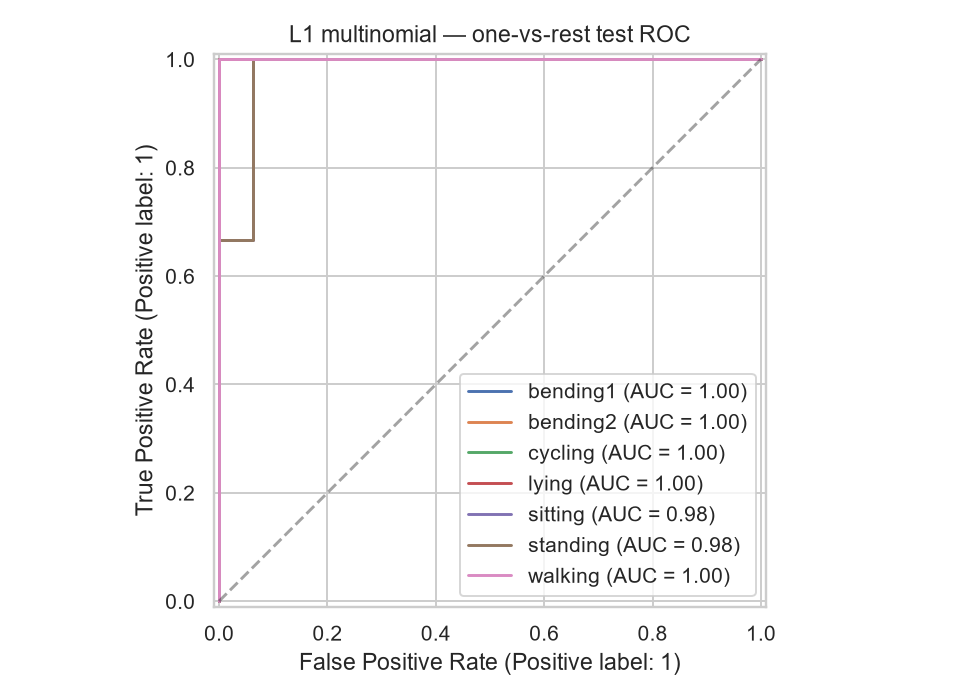

,precision,recall,f1-score,support
bending1,1.0000,1.0000,1.0000,2.0000
bending2,1.0000,1.0000,1.0000,2.0000
cycling,1.0000,1.0000,1.0000,3.0000
lying,1.0000,1.0000,1.0000,3.0000
sitting,0.6667,0.6667,0.6667,3.0000
standing,0.6667,0.6667,0.6667,3.0000
walking,1.0000,1.0000,1.0000,3.0000
accuracy,0.8947,0.8947,0.8947,0.8947
macro avg,0.9048,0.9048,0.9048,19.0000
weighted avg,0.8947,0.8947,0.8947,19.0000


method            L1 multinomial
l                              1
cv_accuracy                  0.9
train_accuracy            0.9855
test_accuracy             0.8947
test_error                0.1053
macro_auc                  0.994
dtype: object

In [9]:
multinomial_pipeline = Pipeline([('scale',StandardScaler()),('model',LogisticRegression(
    solver='saga',l1_ratio=1,max_iter=10000,tol=1e-3,random_state=SEED))])
multi_model,multi_l,multi_search = search_segments('multinomial_l1',multinomial_pipeline,
    {'model__C':[.01,.1,1,10]},ym_train,multi_cv)
print('Final fit iterations:',multi_model.named_steps['model'].n_iter_)

def multiclass_report(model,l,name,cv_table):
    pred = model.predict(Xtest[l])
    probabilities = model.predict_proba(Xtest[l])
    classes = model.classes_
    fig,ax = plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay.from_predictions(ym_test,pred,labels=classes,xticks_rotation=45,
                                           ax=ax,colorbar=False)
    ax.grid(False)
    ax.set_title(name+' — test'); fig.tight_layout()
    fig.savefig(OUT/(name.replace(' ','_')+'_cm.png'),dpi=140); plt.show()
    fig,ax = plt.subplots(figsize=(7,5))
    binary_y = label_binarize(ym_test,classes=classes)
    for j,label in enumerate(classes):
        RocCurveDisplay.from_predictions(binary_y[:,j],probabilities[:,j],name=label,ax=ax)
    ax.plot([0,1],[0,1],'k--',alpha=.4); ax.set_title(name+' — one-vs-rest test ROC')
    fig.tight_layout(); fig.savefig(OUT/(name.replace(' ','_')+'_roc.png'),dpi=140); plt.show()
    display(pd.DataFrame(classification_report(ym_test,pred,output_dict=True,zero_division=0)).T)
    prediction_table = metadata.loc[test_mask,['file','activity']].copy()
    prediction_table['prediction'] = pred
    prediction_table.to_csv(OUT/(name.replace(' ','_')+'_predictions.csv'),index=False)
    return dict(method=name,l=l,cv_accuracy=cv_table.iloc[0].mean_test_score,
                train_accuracy=accuracy_score(ym_train,model.predict(Xtrain[l])),
                test_accuracy=accuracy_score(ym_test,pred),test_error=1-accuracy_score(ym_test,pred),
                macro_auc=roc_auc_score(ym_test,probabilities,labels=classes,multi_class='ovr',average='macro'))

multinomial_metrics = multiclass_report(multi_model,multi_l,'L1 multinomial',multi_search)
display(pd.Series(multinomial_metrics))

The chosen model uses $l=1$ and $C=1$. CV accuracy is 90.00%. On the test set it makes 2 errors
out of 19, giving a test error of 10.53%.

In the confusion matrix, rows show the actual activity and columns show the prediction. One sitting
file is predicted as standing, and one standing file is predicted as sitting. All other test files
are correct. The AUCs are high, but a high AUC does not require the right class to have the largest
probability on every file.

#### (ii) Gaussian and multinomial naive Bayes
For Gaussian NB I tune $l$ with variance smoothing fixed at its default $10^{-9}$.
For multinomial NB I tune $l$ with additive smoothing $\alpha=1$.
Both use the same multiclass CV folds. Gaussian NB uses a training-fitted standard scaler.
Multinomial NB needs nonnegative inputs, so it uses MaxAbsScaler, fitted separately inside each fold.
All seven statistics are nonnegative in these data. The scaled features are not counts, so the
multinomial model is an approximation here. I still evaluate it as requested.

gaussian_nb: l= 1, best CV=0.8571, convergence warnings=0


gaussian_nb: l= 2, best CV=0.8275, convergence warnings=0


gaussian_nb: l= 3, best CV=0.6978, convergence warnings=0


gaussian_nb: l= 4, best CV=0.6967, convergence warnings=0


gaussian_nb: l= 5, best CV=0.6231, convergence warnings=0


...

multinomial_nb: l=18, best CV=0.6967, convergence warnings=0


multinomial_nb: l=19, best CV=0.6967, convergence warnings=0


multinomial_nb: l=20, best CV=0.6967, convergence warnings=0

Chosen: {'l': 5}


,l,mean_test_score,std_test_score
4,5,0.7264,0.0660
2,3,0.7253,0.0502
7,8,0.7121,0.0980
12,13,0.7121,0.0869
14,15,0.7121,0.0980
0,1,0.7121,0.1254
5,6,0.7110,0.0880
6,7,0.7110,0.0755
13,14,0.7110,0.0755
11,12,0.6978,0.1283


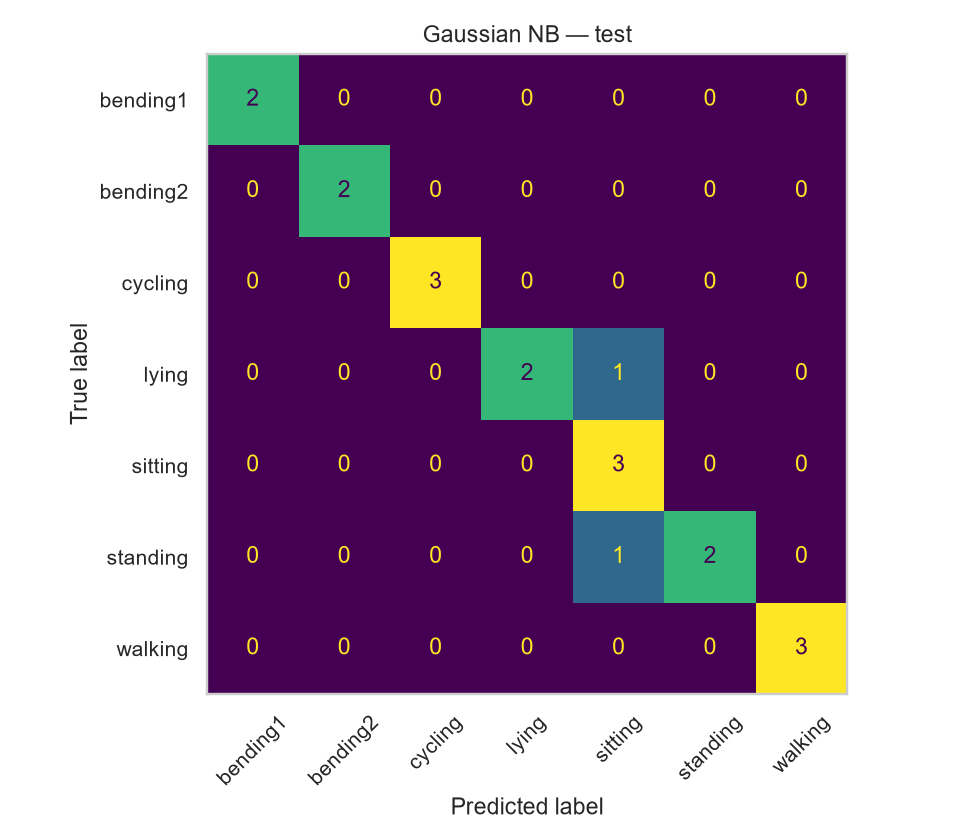

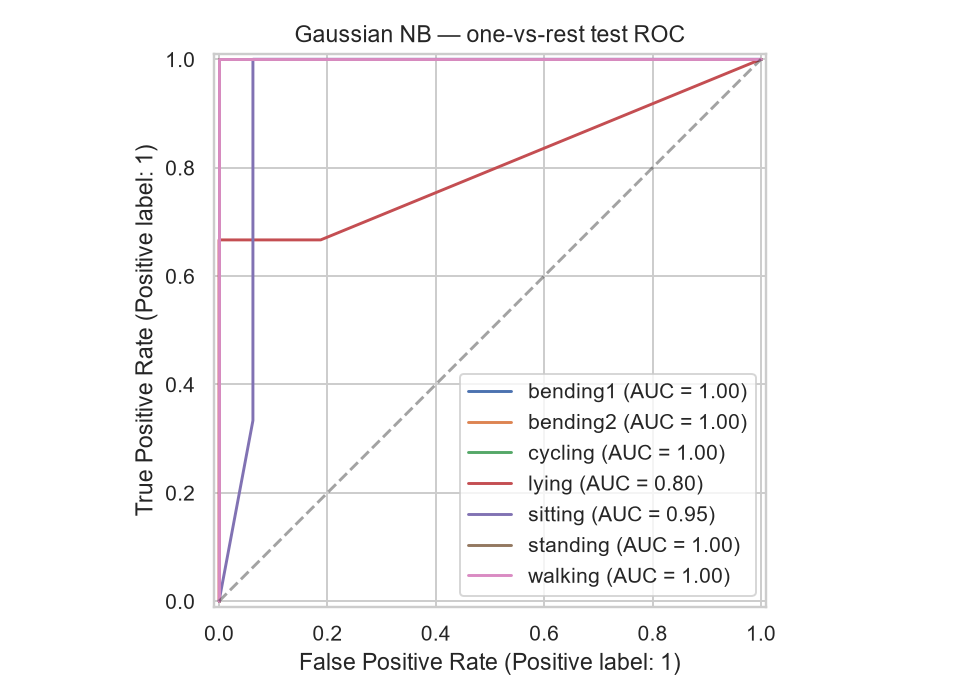

,precision,recall,f1-score,support
bending1,1.0000,1.0000,1.0000,2.0000
bending2,1.0000,1.0000,1.0000,2.0000
cycling,1.0000,1.0000,1.0000,3.0000
lying,1.0000,0.6667,0.8000,3.0000
sitting,0.6000,1.0000,0.7500,3.0000
standing,1.0000,0.6667,0.8000,3.0000
walking,1.0000,1.0000,1.0000,3.0000
accuracy,0.8947,0.8947,0.8947,0.8947
macro avg,0.9429,0.9048,0.9071,19.0000
weighted avg,0.9368,0.8947,0.8974,19.0000


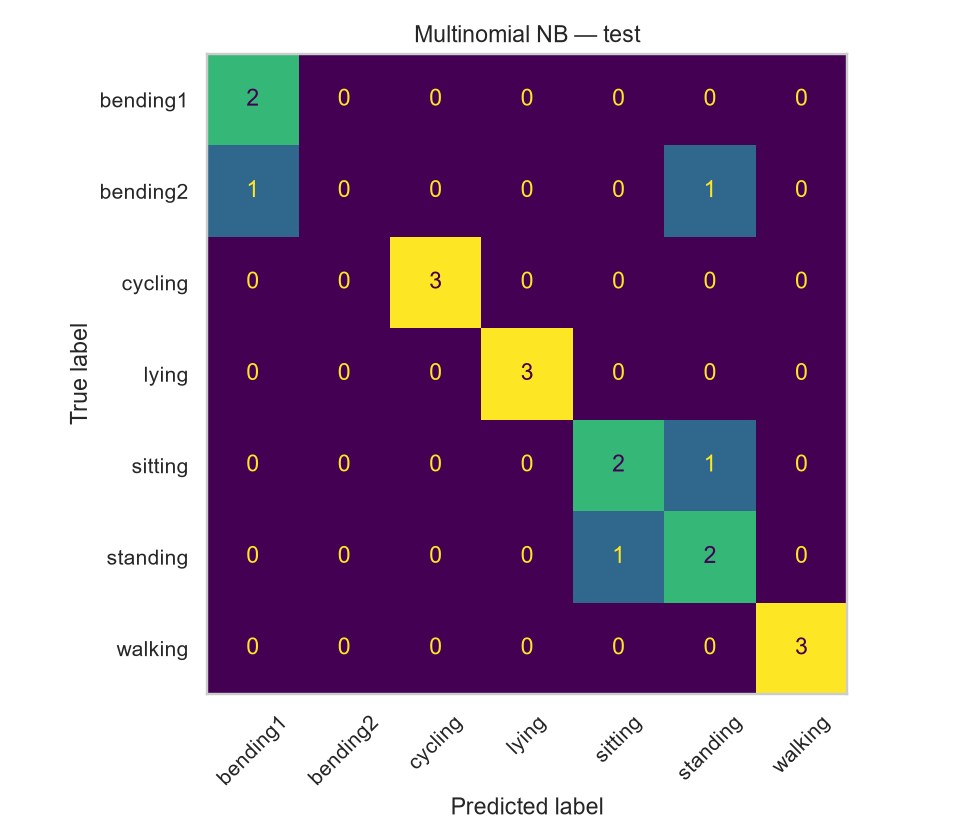

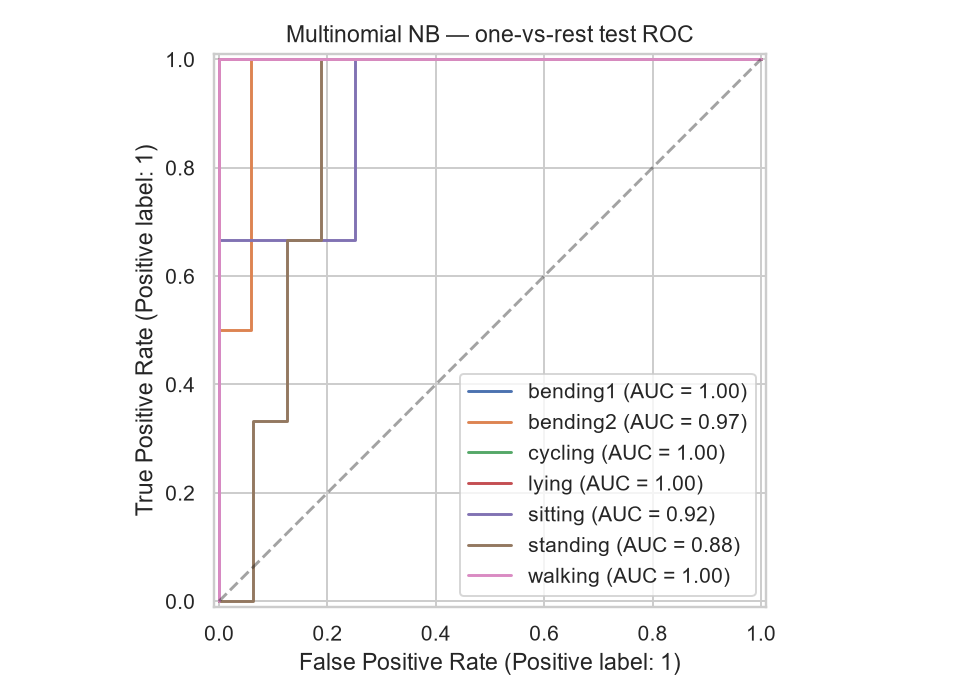

,precision,recall,f1-score,support
bending1,0.6667,1.0000,0.8000,2.0000
bending2,0.0000,0.0000,0.0000,2.0000
cycling,1.0000,1.0000,1.0000,3.0000
lying,1.0000,1.0000,1.0000,3.0000
sitting,0.6667,0.6667,0.6667,3.0000
standing,0.5000,0.6667,0.5714,3.0000
walking,1.0000,1.0000,1.0000,3.0000
accuracy,0.7895,0.7895,0.7895,0.7895
macro avg,0.6905,0.7619,0.7197,19.0000
weighted avg,0.7281,0.7895,0.7534,19.0000


,method,l,cv_accuracy,train_accuracy,test_accuracy,test_error,macro_auc
0,L1 multinomial,1,0.9000,0.9855,0.8947,0.1053,0.9940
1,Gaussian NB,1,0.8571,0.9855,0.8947,0.1053,0.9643
2,Multinomial NB,5,0.7264,0.8551,0.7895,0.2105,0.9660


In [10]:
gnb_pipeline = Pipeline([('scale',StandardScaler()),('model',GaussianNB())])
gnb_model,gnb_l,gnb_cv = search_segments('gaussian_nb',gnb_pipeline,{},ym_train,multi_cv)
mnb_pipeline = Pipeline([('scale',MaxAbsScaler()),('model',MultinomialNB(alpha=1))])
assert all((frame.to_numpy() >= 0).all() for frame in features.values())
mnb_model,mnb_l,mnb_cv = search_segments('multinomial_nb',mnb_pipeline,{},ym_train,multi_cv)
gnb_metrics = multiclass_report(gnb_model,gnb_l,'Gaussian NB',gnb_cv)
mnb_metrics = multiclass_report(mnb_model,mnb_l,'Multinomial NB',mnb_cv)
multiclass_results = pd.DataFrame([multinomial_metrics,gnb_metrics,mnb_metrics])
display(multiclass_results)
multiclass_results.to_csv(OUT/'multiclass_comparison.csv',index=False)

Gaussian NB chooses $l=1$. Its CV accuracy is 85.71% and test error is 10.53%.
Multinomial NB chooses $l=5$, with CV accuracy 72.64% and test error 21.05%.
The features are continuous measurements, so the Gaussian model seems a better fit than a model
for counts. Both NB models assume the features are independent within each class, although several
features in the plots are clearly related.

#### (iii) Which method works better?
I would choose L1 multinomial based on its CV accuracy of 90.00%. Gaussian NB gets 85.71% and
multinomial NB gets 72.64% in CV.

On the test set, L1 multinomial and Gaussian NB both get 17/19 correct (89.47%). Multinomial NB
gets 15/19 (78.95%). So L1 has the better CV result, but it ties with Gaussian NB on this test set.
With only 19 test files, one prediction changes accuracy by about 5.26 percentage points.

## 3. ISLR 2nd edition, Exercise 4.8.3 (page 189)
For class $k$, let $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$ and let $\pi_k=P(Y=k)$.
By Bayes' rule, the best class maximizes $\pi_k f_k(x)$ because the denominator is the same for all classes.
Taking its logarithm gives
$$\log[\pi_k f_k(x)] = \log\pi_k-\frac12\log(2\pi)-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$
The term $-\frac12\log(2\pi)$ is the same for every class. After dropping it and expanding the square,
the discriminant is
$$\delta_k(x)=-\frac{1}{2\sigma_k^2}x^2+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k.$$
This is quadratic in $x$. The Bayes classifier chooses the class with the largest $\delta_k(x)$.
With unequal variances, comparing two classes generally leaves an $x^2$ term, so the decision boundary
is quadratic. If the variances happen to be equal, that term cancels and we get the linear special case.

## 4. ISLR 2nd edition, Exercise 4.8.7 (page 191)
Let $D$ mean that a company issues a dividend. The given values are
$P(D)=0.8$, $P(D^c)=0.2$, $X\mid D\sim N(10,36)$ and $X\mid D^c\sim N(0,36)$.
We want $P(D\mid X=4)$. Using the two normal densities,
$$P(D\mid X=4)=\frac{0.8 f_D(4)}{0.8 f_D(4)+0.2 f_{D^c}(4)}
=\frac{0.8e^{-(4-10)^2/72}}{0.8e^{-(4-10)^2/72}+0.2e^{-(4-0)^2/72}}.$$
The common normalizing constant cancels. The standard deviation is $6$, since the variance is $36$.

In [11]:
dividend_density = norm.pdf(4,loc=10,scale=6)
no_dividend_density = norm.pdf(4,loc=0,scale=6)
posterior = .8*dividend_density/(.8*dividend_density+.2*no_dividend_density)
print(f'P(dividend | X=4) = {posterior:.6f}, or {posterior:.2%}.')

P(dividend | X=4) = 0.751852, or 75.19%.


The probability is about 75.2%. A profit of 4 is closer to the non-dividend mean, so it lowers the
probability from the 80% prior, but issuing a dividend is still more likely.

## References and AI assistance
- [Course AReM dataset description](https://archive.ics.uci.edu/dataset/366/activity+recognition+system+based+on+multisensor+data+fusion+arem).
- [Scikit-learn RFE](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html) and
  [logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [Scikit-learn multiclass ROC example](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html), used for the one-vs-rest plotting approach.
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, second edition,
  Chapter 4, Exercises 3 and 7, pp. 189 and 191. [Book website](https://www.statlearning.com/).

AI assistance was used to look up function usage, refer to example code, draft parts of the code
and explanations, and help check the notebook. The reported results come from running the code above.